# Ada: Acceptance calibration models

1. **Settings.** Synthetic traces until Lucia's `calib.npz` arrives; then set `USE_SYNTHETIC = False`.
2. **Shared code (`mcal/`).** Written to disk by `%%writefile` cells. Lucia's and Alex's code uses the same files, so **don't change function signatures**. Saved models only load where these exact class definitions exist.
3. **Load and check the traces.**
4. **Train/validation split** by prompt, using Lucia's `data_manifest.json` when available.
5. **Sanity checks.** Independent heads mean conditional ≈ marginal; dependent heads mean conditional > marginal.
6. **Tuning.** `alpha` for the count table; `C` and `rank_cap` for the logistic models.
7. **Fit all five scorers.**
8. **Calibration.** Edge-level (P(S_v | parent accepted)) and path-level (P(S_v)), with reliability plots.
9. **Direct-classifier investigation.** Which training pool makes the C2T-style baseline fair.
10. **Feature-group ablation.**
11. **Save models and fixed trees for Alex.**

Only numpy, pandas, scikit-learn and matplotlib are needed; Colab has all of them. No GPU.

## 1. Settings

In [1]:
from pathlib import Path

USE_SYNTHETIC = True            # set False once Lucia's traces arrive

# Where Lucia's files live. In Colab with Drive mounted, for example:
#   from google.colab import drive; drive.mount("/content/drive")
#   DATA_DIR = Path("/content/drive/MyDrive/ECE285_Medusa/20261028_192748_UTC")
DATA_DIR = Path("data")
CALIB_FILE = DATA_DIR / "calib.npz"              # AlpacaEval traces (train + validation prompts)
EVAL_FILE = DATA_DIR / "eval.npz"                # MT-Bench traces (optional for this notebook)
MANIFEST_FILE = DATA_DIR / "data_manifest.json"  # Lucia's fixed train/validation prompt IDs

OUT_DIR = Path("outputs_ada")
SEED = 0
BUDGETS_FOR_ALEX = [8, 16, 32, 63, 96]   # fixed-tree sizes Alex needs
POOL_BUDGET = 64          # nodes per step in the shared candidate pool (MEDUSA+ trees)
POOL_STEPS = 4000         # steps sampled to build pools (lower = faster)
QUICK_EVAL_STEPS = 800    # steps for quick accepted-token checks on validation

Path("mcal").mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

## 2. Shared code (`mcal/`)

Run these cells once per session; they write the package to disk. They are the same files as in `medusa-calib/src/mcal/`.
If you improve something here (a new feature, a new scorer), send the changed file to Alex and Lucia too.

| File | What it holds |
|---|---|
| `traces.py` | `TraceSet`: gold rank of the greedy token in each head's top-10 + head probabilities; synthetic generator |
| `features.py` | node batches, conditional training set, candidate pools, the shared feature map |
| `estimators.py` | the five scorers: `MedusaAccuracy`, `MedusaPlusProb`, `CountConditional`, `LogisticConditional`, `DirectClassifier` |
| `tree.py` | best-first tree selection under a budget; fixed trees in Medusa's `medusa_choices` format |
| `evaluate.py` | accepted tokens from traces, Brier, ECE, reliability, prompt-level bootstrap |

In [2]:
%%writefile mcal/__init__.py
"""Shared code for the ECE 285 Medusa calibration project."""

Overwriting mcal/__init__.py


In [3]:
%%writefile mcal/tree.py
"""Budgeted tree selection (proposal Sec. 3.3).

"At each decoding step, expand high-scoring frontier nodes until reaching B
nodes, always retaining ancestors." Since every scorer guarantees
score(child) <= score(parent), best-first expansion returns the top-B nodes by
score and the selected set is automatically ancestor-closed.

The root (the backbone's own token g_0) is not counted in B, matching the
convention that B is the number of *draft* nodes Medusa verifies.
"""

from __future__ import annotations

import heapq
import itertools

import numpy as np

from .traces import TraceSet


def select_tree(scorer, traces: TraceSet, step: int | None, budget: int,
                max_depth: int | None = None, max_rank: int | None = None) -> list[tuple[tuple, float]]:
    """Return exactly budget nodes, or reject an impossible budget.

    step=None builds a step-independent (fixed) tree; only valid for scorers
    with `dynamic = False`.
    """
    if step is None and getattr(scorer, "dynamic", True):
        raise ValueError(f"{scorer.name} is dynamic; a fixed tree needs a static scorer")
    H = traces.n_heads if max_depth is None else min(max_depth, traces.n_heads)
    K = traces.topk if max_rank is None else min(max_rank, traces.topk)
    if not isinstance(budget, (int, np.integer)) or budget < 0:
        raise ValueError("budget must be a nonnegative integer")
    if H < 1 or K < 1 or budget > sum(K ** d for d in range(1, H + 1)):
        raise ValueError("budget exceeds the candidate tree capacity")
    tie = itertools.count()
    heap: list = []

    def push_children(parent: tuple, pscore: float):
        if len(parent) >= H:
            return
        scores = scorer.child_scores(traces, step, parent, pscore)[:K]
        if len(scores) != K or not np.isfinite(scores).all():
            raise ValueError("scorer must return K finite child scores")
        if np.any(np.asarray(scores) < 0) or np.any(np.asarray(scores) > pscore + 1e-8):
            raise ValueError("child scores must be between zero and the parent score")
        for r, s in enumerate(scores):
            heapq.heappush(heap, (-float(s), next(tie), parent + (r,)))

    push_children((), 1.0)
    tree: list[tuple[tuple, float]] = []
    while heap and len(tree) < budget:
        neg, _, path = heapq.heappop(heap)
        tree.append((path, -neg))
        push_children(path, -neg)
    return tree


def fixed_tree(scorer, traces: TraceSet, budget: int, **kw) -> list[tuple[tuple, float]]:
    """Medusa-style static tree from a step-independent scorer (fit on calibration data)."""
    return select_tree(scorer, traces, None, budget, **kw)


def tree_to_medusa_choices(tree: list[tuple[tuple, float]]) -> list[list[int]]:
    """Convert to Medusa's `medusa_choices` format (list of rank paths, sorted by depth then rank)."""
    return sorted((list(p) for p, _ in tree), key=lambda p: (len(p), p))


def is_ancestor_closed(tree: list[tuple[tuple, float]]) -> bool:
    paths = {p for p, _ in tree}
    return all(p[:-1] in paths or len(p) == 1 for p in paths)


def validate_choices(choices, n_heads=5, topk=10):
    """Validate the rank paths consumed by upstream Medusa buffer construction."""
    paths = [tuple(p) for p in choices]
    if not paths or len(set(paths)) != len(paths):
        raise ValueError("tree must be nonempty and contain unique paths")
    for p in paths:
        if not 1 <= len(p) <= n_heads or any(
            not isinstance(r, (int, np.integer)) or not 0 <= r < topk for r in p
        ):
            raise ValueError("invalid tree depth or candidate rank")
    if not is_ancestor_closed([(p, 0.0) for p in paths]):
        raise ValueError("tree must include every ancestor")
    return sorted([list(p) for p in paths], key=lambda p: (len(p), p))

Overwriting mcal/tree.py


In [4]:
%%writefile mcal/features.py
"""Node batches and features x available *before* verification.

A NodeBatch is a flat list of tree nodes across many decoding steps. Every
learned estimator (logistic conditional, direct classifier) uses the SAME
feature map, so the comparison in the proposal is feature- and
capacity-matched by construction.
"""

from __future__ import annotations

from dataclasses import dataclass

import numpy as np

from .traces import TraceSet

EPS = 1e-6


@dataclass
class NodeBatch:
    step: np.ndarray    # [M] index into TraceSet
    path: np.ndarray    # [M, H] rank path, padded with -1
    depth: np.ndarray   # [M] in 1..H

    def __len__(self) -> int:
        return len(self.step)

    @property
    def own_rank(self) -> np.ndarray:
        return self.path[np.arange(len(self)), self.depth - 1]

    @property
    def parent_rank(self) -> np.ndarray:
        """-1 for depth-1 nodes (their parent is the always-accepted root g_0)."""
        pr = np.full(len(self), -1, dtype=self.path.dtype)
        deep = self.depth > 1
        pr[deep] = self.path[np.where(deep)[0], self.depth[deep] - 2]
        return pr

    @staticmethod
    def concat(parts: list["NodeBatch"]) -> "NodeBatch":
        return NodeBatch(np.concatenate([p.step for p in parts]),
                         np.concatenate([p.path for p in parts]),
                         np.concatenate([p.depth for p in parts]))


# ---------------------------------------------------------------------------
# Training-set builders
# ---------------------------------------------------------------------------

def conditional_nodes(traces: TraceSet, max_rank: int | None = None) -> tuple[NodeBatch, np.ndarray]:
    """All children of *accepted* parents, with label S_v given S_parent = 1.

    "Conditional labels use only calibration examples whose parent prefix was
    accepted" (proposal, Sec. 3.2). Under greedy verification the accepted
    parent at depth d-1 is unique (the gold prefix), so each step contributes
    at most H * K examples.
    """
    K = traces.topk if max_rank is None else min(max_rank, traces.topk)
    H = traces.n_heads
    L = traces.accept_chain_len()               # gold prefix of length L is in candidate space
    steps, paths, depths = [], [], []
    for d in range(1, H + 1):
        # parent (depth d-1) accepted <=> gold prefix of length d-1 is representable
        s = np.where(L >= d - 1)[0]
        if len(s) == 0:
            continue
        p = np.full((len(s), K, H), -1, dtype=np.int16)
        p[:, :, : d - 1] = traces.gold_rank[s, None, : d - 1]
        p[:, :, d - 1] = np.arange(K)[None, :]
        steps.append(np.repeat(s, K))
        paths.append(p.reshape(-1, H))
        depths.append(np.full(len(s) * K, d, dtype=np.int16))
    nb = NodeBatch(np.concatenate(steps), np.concatenate(paths), np.concatenate(depths))
    y = traces.is_accepted(nb.step, nb.path, nb.depth)
    return nb, y


def candidate_pool_nodes(traces: TraceSet, scorer, budget: int, n_steps: int | None = None,
                         seed: int = 0) -> tuple[NodeBatch, np.ndarray]:
    """Nodes from reference trees per step (default: MEDUSA+ prob product).

    Used to (i) train the direct classifier, whose label is full-prefix
    acceptance S_v on nodes whose parents may have failed, and (ii) compute
    path-level Brier scores on the *same* candidate set for every method.

    `scorer` may be a list of scorers: each step then contributes the UNION of
    their trees (duplicates removed), e.g. [MedusaPlusProb(), direct_v1] to
    retrain the direct classifier on nodes its own trees pick.
    """
    from .tree import select_tree  # local import to avoid cycle

    scorers = scorer if isinstance(scorer, (list, tuple)) else [scorer]
    rng = np.random.default_rng(seed)
    idx = np.arange(traces.n_steps)
    if n_steps is not None and n_steps < len(idx):
        idx = rng.choice(idx, n_steps, replace=False)
    H = traces.n_heads
    steps, paths, depths = [], [], []
    for s in idx:
        seen = set()
        for sc in scorers:
            for path, _ in select_tree(sc, traces, int(s), budget):
                if path in seen:
                    continue
                seen.add(path)
                row = np.full(H, -1, dtype=np.int16)
                row[: len(path)] = path
                steps.append(s), paths.append(row), depths.append(len(path))
    nb = NodeBatch(np.array(steps), np.stack(paths), np.array(depths, dtype=np.int16))
    return nb, traces.is_accepted(nb.step, nb.path, nb.depth)


# ---------------------------------------------------------------------------
# Feature map (shared by logistic-conditional and direct classifier)
# ---------------------------------------------------------------------------

FEATURE_GROUPS = ("depth", "own_rank", "parent_rank", "confidence", "path_prob",
                  "uncertainty", "interactions")


def _entropy(p: np.ndarray) -> np.ndarray:
    q = np.clip(p, EPS, 1.0)
    return -(q * np.log(q)).sum(-1)


def node_features(traces: TraceSet, nb: NodeBatch, rank_cap: int = 4,
                  drop: tuple = ()) -> np.ndarray:
    """Features from the proposal: ranks, confidence, depth, parent-child interactions.

    All features are computable before verification (no gold info).
    `drop` removes whole groups (names in FEATURE_GROUPS) for ablations.
    Returns float32 [M, F].
    """
    H = traces.n_heads
    M = len(nb)
    d0 = nb.depth.astype(np.int64) - 1                 # 0-based head index
    r = nb.own_rank.astype(np.int64)
    pr = nb.parent_rank.astype(np.int64)               # -1 = parent is the root token
    has_parent = (nb.depth > 1).astype(np.float32)

    probs = traces.topk_prob[nb.step]                  # [M, H, K]
    own_p = probs[np.arange(M), d0, r]
    par_p = np.where(has_parent > 0, probs[np.arange(M), np.maximum(d0 - 1, 0), np.maximum(pr, 0)],
                     traces.root_prob[nb.step])
    head_top1 = probs[np.arange(M), d0, 0]
    head_ent = _entropy(probs[np.arange(M), d0])

    lp, lpp = np.log(own_p + EPS), np.log(par_p + EPS)
    # log of the MEDUSA+ path score (sum of head log-probs along the path). C2T uses
    # this kind of joint-probability feature; it's shared by both learned models.
    on_path = np.arange(H)[None, :] < nb.depth[:, None]
    pp = probs[np.arange(M)[:, None], np.arange(H)[None, :], np.maximum(nb.path, 0)]
    log_path_p = np.where(on_path, np.log(pp + EPS), 0.0).sum(1)

    def onehot(v, n):
        out = np.zeros((M, n), dtype=np.float32)
        out[np.arange(M), v] = 1
        return out

    col = lambda v: np.asarray(v, dtype=np.float32)[:, None]
    groups = {
        "depth": [onehot(d0, H)],
        # ranks above rank_cap share one bucket; the parent's extra bucket is "root"
        "own_rank": [onehot(np.minimum(r, rank_cap), rank_cap + 1)],
        "parent_rank": [onehot(np.where(has_parent > 0, np.minimum(pr, rank_cap), rank_cap + 1),
                               rank_cap + 2)],
        "confidence": [col(lp), col(lpp), col(own_p / (head_top1 + EPS))],
        "path_prob": [col(log_path_p)],
        "uncertainty": [col(head_ent), col(np.log(traces.root_prob[nb.step] + EPS))],
        "interactions": [col(lp * lpp), col((r == 0) & (pr <= 0)), col(lp * d0)],
    }
    unknown = set(drop) - set(groups)
    if unknown:
        raise ValueError(f"unknown feature groups {unknown}; choose from {FEATURE_GROUPS}")
    feats = [f for name in FEATURE_GROUPS if name not in drop for f in groups[name]]
    return np.concatenate(feats, axis=1).astype(np.float32)

Overwriting mcal/features.py


In [5]:
%%writefile mcal/estimators.py
"""Path scorers compared in the proposal.

Every scorer exposes the same two methods so tree selection and evaluation
are identical across methods (matched candidates, procedure, budget):

    child_scores(traces, step, parent_path, parent_score) -> [K] path scores
    path_scores(traces, nodes)                            -> [M] path scores

Edge-factor scorers define factor(traces, nodes) = estimate for the LAST edge
of each node and score a path by the product of its factors (Eq. 1):

    P_hat(S_v | x) = prod_{e in path(v)} q_hat_e(x)

  name               factor q_e                                  tree
  -----------------  ------------------------------------------  ---------
  MedusaAccuracy     marginal acc of (head, rank)                fixed     (original Medusa)
  MedusaPlusProb     head softmax prob p_{j, r_j}                dynamic   (MEDUSA+)
  CountConditional   smoothed P(S_v | S_u, head, rank, parent rank)  fixed (ours, step 1)
  LogisticConditional  logistic P(S_v | S_u, x)                  dynamic   (ours)
  DirectClassifier   logistic P(S_v | x) on the FULL prefix      dynamic   (C2T-inspired baseline)

Because every q_e is in [0, 1], child scores never exceed parent scores, which
is what lets best-first selection keep the tree ancestor-closed.
"""

from __future__ import annotations

import pickle
from pathlib import Path

import numpy as np

from .features import NodeBatch, conditional_nodes, node_features
from .traces import TraceSet


class Scorer:
    name = "base"
    dynamic = True   # False => scores don't depend on the step (fixed tree)

    # -- to implement ----------------------------------------------------
    def fit(self, traces: TraceSet, **kw) -> "Scorer":
        return self

    def factor(self, traces: TraceSet, nodes: NodeBatch) -> np.ndarray:
        raise NotImplementedError

    # -- shared ----------------------------------------------------------
    def child_scores(self, traces: TraceSet, step: int | None, parent_path: tuple,
                     parent_score: float) -> np.ndarray:
        nodes = _children(traces, step, parent_path)
        return parent_score * self.factor(traces, nodes)

    def path_scores(self, traces: TraceSet, nodes: NodeBatch) -> np.ndarray:
        score = np.ones(len(nodes))
        for d in range(1, int(nodes.depth.max()) + 1):
            m = nodes.depth >= d
            pref = NodeBatch(nodes.step[m], _truncate(nodes.path[m], d), np.full(m.sum(), d, dtype=np.int16))
            score[m] *= self.factor(traces, pref)
        return score

    def save(self, path: str | Path) -> None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        with open(path, "wb") as f:
            pickle.dump(self, f)

    @staticmethod
    def load(path: str | Path) -> "Scorer":
        with open(path, "rb") as f:
            return pickle.load(f)


def _truncate(path: np.ndarray, d: int) -> np.ndarray:
    out = path.copy()
    out[:, d:] = -1
    return out


def _children(traces: TraceSet, step: int | None, parent_path: tuple) -> NodeBatch:
    H, K, d = traces.n_heads, traces.topk, len(parent_path) + 1
    path = np.full((K, H), -1, dtype=np.int16)
    path[:, : d - 1] = parent_path
    path[:, d - 1] = np.arange(K)
    s = np.zeros(K, dtype=np.int64) if step is None else np.full(K, step, dtype=np.int64)
    return NodeBatch(s, path, np.full(K, d, dtype=np.int16))


# ---------------------------------------------------------------------------
# Baselines
# ---------------------------------------------------------------------------

class MedusaAccuracy(Scorer):
    """Original Medusa: product of per-(head, rank) marginal top-k accuracies."""
    name, dynamic = "medusa_acc", False

    def fit(self, traces, **kw):
        H, K = traces.n_heads, traces.topk
        self.acc = np.stack([[(traces.gold_rank[:, j] == r).mean() for r in range(K)] for j in range(H)])
        return self

    def factor(self, traces, nodes):
        return self.acc[nodes.depth - 1, nodes.own_rank]


class MedusaPlusProb(Scorer):
    """MEDUSA+: product of head softmax probabilities (no fitting)."""
    name, dynamic = "medusa_plus", True

    def factor(self, traces, nodes):
        return traces.topk_prob[nodes.step, nodes.depth - 1, nodes.own_rank].astype(np.float64)


# ---------------------------------------------------------------------------
# Ours
# ---------------------------------------------------------------------------

class CountConditional(Scorer):
    """Smoothed count table q[head, parent_rank, rank] = P(S_v | S_u = 1).

    Indexed by head and preceding-token rank (proposal Sec. 3.2). Smoothing
    shrinks toward the marginal-accuracy factor with strength `alpha`, so
    rare cells fall back to the original Medusa estimate.
    Parent rank index K is reserved for "parent = root" (depth-1 nodes).
    """
    name, dynamic = "count_cond", False

    def __init__(self, alpha: float = 20.0):
        self.alpha = alpha

    def fit(self, traces, nodes=None, **kw):
        H, K = traces.n_heads, traces.topk
        nb, y = conditional_nodes(traces) if nodes is None else nodes
        pr = np.where(nb.depth > 1, nb.parent_rank, K)
        d0, r = nb.depth - 1, nb.own_rank
        hits = np.zeros((H, K + 1, K))
        tot = np.zeros((H, K + 1, K))
        np.add.at(tot, (d0, pr, r), 1)
        np.add.at(hits, (d0, pr, r), y)
        # prior: P(S_v | S_u) pooled over parent ranks
        prior = hits.sum(1) / np.maximum(tot.sum(1), 1)            # [H, K]
        self.q = (hits + self.alpha * prior[:, None, :]) / (tot + self.alpha)
        self.counts = tot
        return self

    def factor(self, traces, nodes):
        K = traces.topk
        pr = np.where(nodes.depth > 1, nodes.parent_rank, K)
        return self.q[nodes.depth - 1, pr, nodes.own_rank]


class _Logistic:
    """Tiny numpy-side wrapper so prediction inside the tree loop is fast."""

    def __init__(self, C: float = 1.0, max_iter: int = 2000):
        self.C, self.max_iter = C, max_iter

    def fit(self, X, y, sample_weight=None):
        from sklearn.linear_model import LogisticRegression
        from sklearn.preprocessing import StandardScaler
        self.scaler = StandardScaler().fit(X)
        clf = LogisticRegression(C=self.C, max_iter=self.max_iter)
        clf.fit(self.scaler.transform(X), y.astype(int), sample_weight=sample_weight)
        self.w, self.b = clf.coef_[0], clf.intercept_[0]
        return self

    def predict_proba(self, X):
        z = ((X - self.scaler.mean_) / self.scaler.scale_) @ self.w + self.b
        return 1 / (1 + np.exp(-z))


class LogisticConditional(Scorer):
    """Logistic regression for q_v(x) = P(S_v | S_u = 1, x), trained on accepted-parent nodes."""
    name, dynamic = "logistic_cond", True

    def __init__(self, C: float = 1.0, rank_cap: int = 4, drop: tuple = ()):
        self.C, self.rank_cap, self.drop = C, rank_cap, tuple(drop)

    def _X(self, traces, nodes):
        return node_features(traces, nodes, self.rank_cap, getattr(self, "drop", ()))

    def fit(self, traces, nodes=None, **kw):
        """nodes: optional precomputed conditional_nodes(traces) to save time in sweeps."""
        nb, y = conditional_nodes(traces) if nodes is None else nodes
        self.model = _Logistic(self.C).fit(self._X(traces, nb), y)
        return self

    def factor(self, traces, nodes):
        return self.model.predict_proba(self._X(traces, nodes))


class DirectClassifier(Scorer):
    """C2T-inspired baseline: one classifier predicts full-prefix acceptance P(S_v | x).

    Same features and capacity (one logistic layer) as LogisticConditional;
    the only difference is the *target*: unconditional S_v on a candidate pool
    rather than S_v | S_u = 1. With monotone=True a child's score is capped at
    its parent's so best-first selection stays ancestor-closed (document this
    choice in the report; C2T itself prunes by threshold).
    """
    name, dynamic = "direct", True

    def __init__(self, C: float = 1.0, rank_cap: int = 4, monotone: bool = True, drop: tuple = ()):
        self.C, self.rank_cap, self.monotone, self.drop = C, rank_cap, monotone, tuple(drop)

    def fit(self, traces, pool: tuple[NodeBatch, np.ndarray] | None = None, **kw):
        if pool is None:
            raise ValueError("DirectClassifier needs a candidate pool: see features.candidate_pool_nodes")
        nb, y = pool
        self.model = _Logistic(self.C).fit(self._X(traces, nb), y)
        return self

    def _X(self, traces, nodes):
        return node_features(traces, nodes, self.rank_cap, getattr(self, "drop", ()))

    def _raw(self, traces, nodes):
        return self.model.predict_proba(self._X(traces, nodes))

    def child_scores(self, traces, step, parent_path, parent_score):
        s = self._raw(traces, _children(traces, step, parent_path))
        return np.minimum(s, parent_score) if self.monotone else s

    def path_scores(self, traces, nodes):
        s = self._raw(traces, nodes)
        if not self.monotone:
            return s
        for d in range(1, int(nodes.depth.max())):   # cap by every ancestor
            m = nodes.depth > d
            pref = NodeBatch(nodes.step[m], _truncate(nodes.path[m], d), np.full(m.sum(), d, dtype=np.int16))
            s[m] = np.minimum(s[m], self._raw(traces, pref))
        return s


REGISTRY = {c.name: c for c in [MedusaAccuracy, MedusaPlusProb, CountConditional,
                                LogisticConditional, DirectClassifier]}

Overwriting mcal/estimators.py


In [6]:
%%writefile mcal/tree.py
"""Budgeted tree selection (proposal Sec. 3.3).

"At each decoding step, expand high-scoring frontier nodes until reaching B
nodes, always retaining ancestors." Since every scorer guarantees
score(child) <= score(parent), best-first expansion returns the top-B nodes by
score and the selected set is automatically ancestor-closed.

The root (the backbone's own token g_0) is not counted in B, matching the
convention that B is the number of *draft* nodes Medusa verifies.
"""

from __future__ import annotations

import heapq
import itertools

import numpy as np

from .traces import TraceSet


def select_tree(scorer, traces: TraceSet, step: int | None, budget: int,
                max_depth: int | None = None, max_rank: int | None = None) -> list[tuple[tuple, float]]:
    """Return [(rank_path, path_score), ...] of length <= budget, in selection order.

    step=None builds a step-independent (fixed) tree; only valid for scorers
    with `dynamic = False`.
    """
    if step is None and getattr(scorer, "dynamic", True):
        raise ValueError(f"{scorer.name} is dynamic; a fixed tree needs a static scorer")
    H = traces.n_heads if max_depth is None else min(max_depth, traces.n_heads)
    K = traces.topk if max_rank is None else min(max_rank, traces.topk)
    tie = itertools.count()
    heap: list = []

    def push_children(parent: tuple, pscore: float):
        if len(parent) >= H:
            return
        scores = scorer.child_scores(traces, step, parent, pscore)[:K]
        for r, s in enumerate(scores):
            heapq.heappush(heap, (-float(s), next(tie), parent + (r,)))

    push_children((), 1.0)
    tree: list[tuple[tuple, float]] = []
    while heap and len(tree) < budget:
        neg, _, path = heapq.heappop(heap)
        tree.append((path, -neg))
        push_children(path, -neg)
    return tree


def fixed_tree(scorer, traces: TraceSet, budget: int, **kw) -> list[tuple[tuple, float]]:
    """Medusa-style static tree from a step-independent scorer (fit on calibration data)."""
    return select_tree(scorer, traces, None, budget, **kw)


def tree_to_medusa_choices(tree: list[tuple[tuple, float]]) -> list[list[int]]:
    """Convert to Medusa's `medusa_choices` format (list of rank paths, sorted by depth then rank)."""
    return sorted((list(p) for p, _ in tree), key=lambda p: (len(p), p))


def is_ancestor_closed(tree: list[tuple[tuple, float]]) -> bool:
    paths = {p for p, _ in tree}
    return all(p[:-1] in paths or len(p) == 1 for p in paths)

Overwriting mcal/tree.py


In [7]:
%%writefile mcal/evaluate.py
"""Trace-simulated evaluation.

Primary metric (proposal Sec. 5): mean accepted tokens per verification step
at matched budget B. On traces this is exact for greedy verification:

    accepted(T) = 1 + |{v in T : S_v = 1}|     (the 1 is the backbone's g_0)

and a calibrated scorer predicts it as 1 + sum_{v in T} P_hat(S_v | x).

IMPORTANT: numbers from this module are *trace-only*. Per the proposal they
must not be reported as speedups; wall-clock tokens/sec comes from decode.py.
"""

from __future__ import annotations

import time

import numpy as np

from .features import NodeBatch
from .traces import TraceSet
from .tree import select_tree


def accepted_tokens(traces: TraceSet, step: int, tree_paths: set[tuple]) -> int:
    gold = traces.gold_rank[step]
    n = 0
    for d in range(1, traces.n_heads + 1):
        if gold[d - 1] < 0 or tuple(int(g) for g in gold[:d]) not in tree_paths:
            break
        n += 1
    return 1 + n


def evaluate_tree_policy(scorer, traces: TraceSet, budget: int, fixed=None,
                         steps: np.ndarray | None = None) -> dict:
    """Evaluate a scorer with dynamic per-step trees, or a given fixed tree.

    fixed: output of tree.fixed_tree(...) to evaluate a static tree instead.
    """
    steps = np.arange(traces.n_steps) if steps is None else steps
    acc, pred, build_t = np.zeros(len(steps)), np.zeros(len(steps)), np.zeros(len(steps))
    if fixed is not None:
        fixed_set = {p for p, _ in fixed}
    for i, s in enumerate(steps):
        s = int(s)
        if fixed is None:
            t0 = time.perf_counter()
            tree = select_tree(scorer, traces, s, budget)
            build_t[i] = time.perf_counter() - t0
            paths = {p for p, _ in tree}
            pred[i] = 1 + sum(sc for _, sc in tree)
        else:
            paths = fixed_set
            pred[i] = 1 + sum(sc for _, sc in fixed)
        acc[i] = accepted_tokens(traces, s, paths)
    return dict(
        method=scorer.name if fixed is None else f"{scorer.name}[fixed]",
        budget=budget,
        mean_accepted=float(acc.mean()),
        sem_accepted=float(acc.std(ddof=1) / np.sqrt(len(acc))),
        mean_predicted=float(pred.mean()),
        tree_build_ms=float(build_t.mean() * 1e3),  # Python-side; NOT representative of a GPU impl
        n_steps=len(steps),
        per_step_accepted=acc,
    )


def paired_bootstrap(a: np.ndarray, b: np.ndarray, groups: np.ndarray, n_boot: int = 2000,
                     seed: int = 0) -> tuple[float, float, float]:
    """Mean of (a - b) with a 95% CI, resampling *prompts* (steps within a prompt are correlated)."""
    rng = np.random.default_rng(seed)
    diff = a - b
    uniq, inv = np.unique(groups, return_inverse=True)
    sums = np.bincount(inv, weights=diff, minlength=len(uniq))
    cnts = np.bincount(inv, minlength=len(uniq))
    boots = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(uniq), len(uniq))
        boots[i] = sums[idx].sum() / cnts[idx].sum()
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return float(diff.mean()), float(lo), float(hi)


def brier(p: np.ndarray, y: np.ndarray) -> float:
    return float(np.mean((p - y.astype(float)) ** 2))


def ece(p: np.ndarray, y: np.ndarray, n_bins: int = 15) -> float:
    bins = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    out = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            out += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(out)


def reliability(p: np.ndarray, y: np.ndarray, n_bins: int = 10) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """(mean predicted, observed rate, count) per bin, for reliability diagrams."""
    bins = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    mp, obs, cnt = [], [], []
    for b in range(n_bins):
        m = bins == b
        if m.any():
            mp.append(p[m].mean()), obs.append(y[m].mean()), cnt.append(m.sum())
    return np.array(mp), np.array(obs), np.array(cnt)


def calibration_report(scorer, traces: TraceSet, pool: tuple[NodeBatch, np.ndarray]) -> dict:
    """Path-level calibration of P_hat(S_v | x) on a shared candidate pool."""
    nb, y = pool
    p = np.clip(scorer.path_scores(traces, nb), 0, 1)
    return dict(method=scorer.name, brier=brier(p, y), ece=ece(p, y),
                mean_pred=float(p.mean()), mean_obs=float(y.mean()))

Overwriting mcal/evaluate.py


## 3. Load and check the traces

In [8]:
import importlib, json, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mcal.traces, mcal.features, mcal.estimators, mcal.tree, mcal.evaluate
for m in [mcal.traces, mcal.features, mcal.estimators, mcal.tree, mcal.evaluate]:
    importlib.reload(m)   # picks up edits after re-running the %%writefile cells

from mcal.traces import TraceSet, make_synthetic_traces
from mcal.features import (NodeBatch, conditional_nodes, candidate_pool_nodes,
                           node_features, FEATURE_GROUPS)
from mcal.estimators import (Scorer, MedusaAccuracy, MedusaPlusProb, CountConditional,
                             LogisticConditional, DirectClassifier)
from mcal.tree import select_tree, fixed_tree, tree_to_medusa_choices, is_ancestor_closed
from mcal.evaluate import evaluate_tree_policy, brier, ece, reliability

pd.set_option("display.precision", 4)

In [9]:
if USE_SYNTHETIC:
    calib = make_synthetic_traces(n_prompts=250, steps_per_prompt=120, seed=SEED)
    evals = make_synthetic_traces(n_prompts=80, steps_per_prompt=120, seed=SEED + 100)
else:
    calib = TraceSet.load(CALIB_FILE)
    evals = TraceSet.load(EVAL_FILE) if EVAL_FILE.exists() else None

print(calib.summary())
print(evals.summary() if evals is not None else "No eval traces yet: eval-set calibration is skipped.")
print("metadata:", calib.meta)

TraceSet: 30000 steps, 250 prompts, H=5, K=10
  head top-1 acc: [0.612, 0.512, 0.408, 0.31, 0.226]
  mean oracle chain length (top-K, infinite tree): 4.175
TraceSet: 9600 steps, 80 prompts, H=5, K=10
  head top-1 acc: [0.621, 0.512, 0.413, 0.309, 0.233]
  mean oracle chain length (top-K, infinite tree): 4.205
metadata: {'source': 'synthetic', 'dependence': 1.0, 'seed': 0}


In [10]:
def check_traces(ts, name):
    """Catch format problems in Lucia's export before they turn into strange results."""
    H, K = ts.n_heads, ts.topk
    problems = []
    if ts.topk_prob.shape != (ts.n_steps, H, K):
        problems.append(f"topk_prob shape {ts.topk_prob.shape}, expected {(ts.n_steps, H, K)}")
    if ts.gold_rank.min() < -1 or ts.gold_rank.max() >= K:
        problems.append("gold_rank outside [-1, K-1]")
    p = ts.topk_prob
    if (p < 0).any() or (p.sum(-1) > 1 + 1e-3).any():
        problems.append("head probabilities negative or summing above 1")
    if (np.diff(p, axis=-1) > 1e-6).any():
        problems.append("top-K probabilities not sorted high to low")
    if not ((ts.root_prob > 0) & (ts.root_prob <= 1 + 1e-6)).all():
        problems.append("root_prob outside (0, 1]")
    if K != 10:
        problems.append(f"K = {K}; Medusa's TOPK is 10")
    if len(np.unique(ts.prompt_id)) < 2:
        problems.append("fewer than 2 prompts: a prompt-level split is impossible")
    print(f"{name}: " + ("format OK" if not problems else "PROBLEMS: " + "; ".join(problems)))

    ranks = pd.DataFrame(
        {f"head {j + 1}": np.bincount(ts.gold_rank[:, j] + 1, minlength=K + 1) / ts.n_steps
         for j in range(H)},
        index=["not in top-10"] + [f"rank {r}" for r in range(K)]).T
    display(ranks.round(3))
    # If ranks 5-9 are nearly empty for deep heads, the export may be limited to the
    # default 63-node tree instead of all top-10 ranks; ask Lucia.

check_traces(calib, "calib")
if evals is not None:
    check_traces(evals, "eval")

calib: format OK


,not in top-10,rank 0,rank 1,rank 2,rank 3,rank 4,rank 5,rank 6,rank 7,rank 8,rank 9
head 1,0.026,0.612,0.124,0.079,0.053,0.034,0.025,0.018,0.013,0.009,0.007
head 2,0.050,0.512,0.133,0.091,0.063,0.046,0.034,0.025,0.019,0.015,0.012
head 3,0.083,0.408,0.137,0.100,0.074,0.058,0.044,0.034,0.025,0.021,0.017
head 4,0.128,0.310,0.141,0.106,0.080,0.064,0.050,0.042,0.030,0.027,0.022
head 5,0.180,0.226,0.134,0.108,0.084,0.067,0.055,0.046,0.040,0.033,0.027


eval: format OK


,not in top-10,rank 0,rank 1,rank 2,rank 3,rank 4,rank 5,rank 6,rank 7,rank 8,rank 9
head 1,0.026,0.621,0.126,0.076,0.048,0.033,0.022,0.019,0.013,0.009,0.007
head 2,0.049,0.512,0.139,0.092,0.065,0.043,0.034,0.023,0.017,0.014,0.011
head 3,0.078,0.413,0.139,0.100,0.071,0.058,0.043,0.034,0.026,0.021,0.018
head 4,0.117,0.309,0.140,0.113,0.084,0.063,0.052,0.041,0.034,0.026,0.021
head 5,0.179,0.233,0.133,0.106,0.083,0.068,0.053,0.046,0.039,0.031,0.029


## 4. Train/validation split

Always split by prompt (steps within one prompt are correlated). With real data, use Lucia's fixed 200/50 split
so every result in the report uses the same held-out prompts. The pilot (20 training prompts) has no
validation prompts yet; it falls back to a random 80/20 prompt split until the full set arrives.

In [11]:
def split_train_val(calib):
    if not USE_SYNTHETIC and MANIFEST_FILE.exists():
        man = json.loads(MANIFEST_FILE.read_text())
        train, val = calib.split_by_prompt_ids(man["train_prompt_ids"])
        if len(np.unique(val.prompt_id)) >= 5:
            unexpected = set(np.unique(val.prompt_id).tolist()) - set(man["validation_prompt_ids"])
            if unexpected:
                print("WARNING: prompts in neither manifest list:", sorted(unexpected)[:10])
            return train, val, "Lucia's manifest"
        print("Manifest split leaves < 5 validation prompts (pilot data?).")
    train, val = calib.split_by_prompt(0.8, seed=SEED)
    return train, val, "random 80/20 prompt split"

train, val, split_how = split_train_val(calib)
print(f"Split: {split_how}")
print(f"  train: {train.n_steps} steps, {len(np.unique(train.prompt_id))} prompts")
print(f"  val:   {val.n_steps} steps, {len(np.unique(val.prompt_id))} prompts")

t0 = time.time()
train_cond = conditional_nodes(train)   # children of accepted parents, labels S_v | S_u = 1
val_cond = conditional_nodes(val)
print(f"conditional training nodes: train {len(train_cond[0])}, val {len(val_cond[0])} "
      f"({time.time() - t0:.1f}s)")

Split: random 80/20 prompt split
  train: 24000 steps, 200 prompts
  val:   6000 steps, 50 prompts
conditional training nodes: train 1086600, val 270740 (0.1s)


## 5. Sanity checks

With independent heads, P(head j correct | earlier heads correct) equals the marginal accuracy, so the
count-based conditional must match the product. With dependent heads it must be higher.
If either fails, it's a bug, not a finding. The last table shows the same comparison on the training data.

In [12]:
rows = []
for dep in [0.0, 1.0]:
    t = make_synthetic_traces(200, 100, dependence=dep, seed=1)
    acc = MedusaAccuracy().fit(t)
    cnt = CountConditional(alpha=1e-9).fit(t)      # no smoothing = raw empirical rates
    for j in range(1, t.n_heads):
        rows.append(dict(dependence=dep, head=j + 1, marginal_top1=acc.acc[j, 0],
                         cond_given_parent_top1=cnt.q[j, 0, 0]))
sanity = pd.DataFrame(rows)
sanity["gap"] = sanity.cond_given_parent_top1 - sanity.marginal_top1
display(sanity.round(3))

indep = sanity[sanity.dependence == 0]
dep = sanity[sanity.dependence == 1]
assert indep.gap.abs().max() < 0.03, "independent heads: conditional should match marginal"
assert (dep.gap > 0.03).all(), "dependent heads: conditional should exceed marginal"
print("Sanity checks passed.")

acc_tr = MedusaAccuracy().fit(train)
cnt_tr = CountConditional(alpha=1e-9).fit(train)
display(pd.DataFrame([dict(head=j + 1, marginal_top1=acc_tr.acc[j, 0],
                           cond_given_parent_top1=cnt_tr.q[j, 0, 0],
                           n_parent_cases=int(cnt_tr.counts[j, 0, 0]))
                      for j in range(1, train.n_heads)]).round(3))

,dependence,head,marginal_top1,cond_given_parent_top1,gap
0,0.0,2,0.509,0.511,0.001
1,0.0,3,0.398,0.398,0.001
2,0.0,4,0.290,0.288,-0.002
3,0.0,5,0.212,0.218,0.005
4,1.0,2,0.509,0.571,0.062
5,1.0,3,0.401,0.489,0.088
6,1.0,4,0.304,0.406,0.102
7,1.0,5,0.224,0.326,0.102


Sanity checks passed.


,head,marginal_top1,cond_given_parent_top1,n_parent_cases
0,2,0.514,0.588,14705
1,3,0.408,0.497,12178
2,4,0.311,0.421,9493
3,5,0.227,0.333,6992


## 6. Tuning on the validation prompts

**Count table `alpha`.** Smoothing shrinks each cell (head, parent rank, rank) toward the same cell pooled
over parent ranks. Very large `alpha` = no parent-rank context at all (the "conditional on acceptance only"
ablation), so the right end of this curve is that ablation for free.

**Logistic `C` and `rank_cap`.** The direct classifier reuses the winning values, so both learned models
keep the same features and capacity.

Scored by Brier score on the validation conditional nodes, which is exactly what the edge factor
q = P(S_v | S_u = 1) is supposed to predict.

,alpha,brier,log_loss
0,1.0000e-01,0.0669,0.2395
1,1.0000e+00,0.0669,0.2395
2,3.0000e+00,0.0669,0.2395
3,1.0000e+01,0.0669,0.2395
4,3.0000e+01,0.0669,0.2395
5,1.0000e+02,0.0669,0.2395
6,3.0000e+02,0.0669,0.2395
7,1.0000e+03,0.0669,0.2396
8,1.0000e+09,0.0673,0.2406


BEST_ALPHA = 100.0


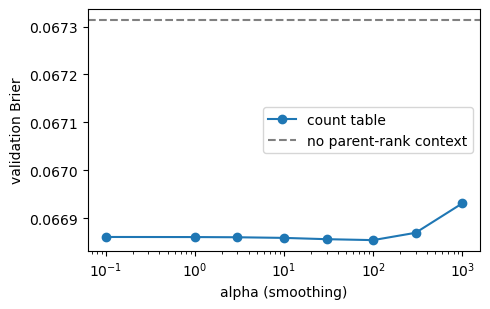

In [13]:
def log_loss(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

alpha_rows = []
for a in [0.1, 1, 3, 10, 30, 100, 300, 1000, 1e9]:
    sc = CountConditional(alpha=a).fit(train, nodes=train_cond)
    p = sc.factor(val, val_cond[0])
    alpha_rows.append(dict(alpha=a, brier=brier(p, val_cond[1]), log_loss=log_loss(p, val_cond[1])))
alpha_df = pd.DataFrame(alpha_rows)
BEST_ALPHA = float(alpha_df.loc[alpha_df.brier.idxmin(), "alpha"])
display(alpha_df)
print("BEST_ALPHA =", BEST_ALPHA)

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogx(alpha_df.alpha[:-1], alpha_df.brier[:-1], "o-", label="count table")
ax.axhline(alpha_df.brier.iloc[-1], ls="--", c="gray", label="no parent-rank context")
ax.set_xlabel("alpha (smoothing)"); ax.set_ylabel("validation Brier"); ax.legend()
fig.tight_layout(); fig.savefig(OUT_DIR / "alpha_tuning.png", dpi=150); plt.show()

In [14]:
t0 = time.time()
grid_rows = []
for rank_cap in [4, 9]:
    for C in [0.1, 1.0, 10.0]:
        sc = LogisticConditional(C=C, rank_cap=rank_cap).fit(train, nodes=train_cond)
        p = sc.factor(val, val_cond[0])
        grid_rows.append(dict(rank_cap=rank_cap, C=C, brier=brier(p, val_cond[1]),
                              log_loss=log_loss(p, val_cond[1])))
grid_df = pd.DataFrame(grid_rows).sort_values("brier")
best = grid_df.iloc[0]
BEST_C, BEST_RANK_CAP = float(best.C), int(best.rank_cap)
display(grid_df)
print(f"BEST_C = {BEST_C}, BEST_RANK_CAP = {BEST_RANK_CAP}  ({time.time() - t0:.0f}s)")

,rank_cap,C,brier,log_loss
5,9,10.0,0.0637,0.2326
4,9,1.0,0.0637,0.2326
3,9,0.1,0.0637,0.2326
2,4,10.0,0.0638,0.2328
1,4,1.0,0.0638,0.2328
0,4,0.1,0.0638,0.2328


BEST_C = 10.0, BEST_RANK_CAP = 9  (53s)


## 7. Fit all five scorers

The direct classifier needs a candidate pool: the nodes of a MEDUSA+ tree of `POOL_BUDGET` nodes at
sampled steps, labeled with full-prefix acceptance S_v (parents may have failed). Section 9 tests
whether a different pool makes it a stronger baseline.

In [15]:
t0 = time.time()
ref = MedusaPlusProb()
pool_train = candidate_pool_nodes(train, ref, POOL_BUDGET, POOL_STEPS, seed=SEED)
print(f"direct-classifier pool: {len(pool_train[0])} nodes, "
      f"acceptance rate {pool_train[1].mean():.3f} ({time.time() - t0:.0f}s)")

scorers = {
    "medusa_acc": MedusaAccuracy().fit(train),
    "medusa_plus": ref,
    "count_cond": CountConditional(alpha=BEST_ALPHA).fit(train, nodes=train_cond),
    "logistic_cond": LogisticConditional(C=BEST_C, rank_cap=BEST_RANK_CAP).fit(train, nodes=train_cond),
    "direct": DirectClassifier(C=BEST_C, rank_cap=BEST_RANK_CAP).fit(train, pool=pool_train),
}
print("fitted:", list(scorers), f"({time.time() - t0:.0f}s total)")

direct-classifier pool: 256000 nodes, acceptance rate 0.041 (10s)
fitted: ['medusa_acc', 'medusa_plus', 'count_cond', 'logistic_cond', 'direct'] (23s total)


## 8. Calibration

* **Edge level** (validation conditional nodes): does each factor predict P(S_v | parent accepted)?
  Marginal-product factors are not meant to, and that gap is the project's claim. The direct classifier
  has no edge factor, so it appears only at path level.
* **Path level** (shared MEDUSA+ candidate pool): does each scorer's path score predict P(S_v)?
  Every method is scored on the same nodes.

In [16]:
edge_rows, edge_curves = [], {}
for name in ["medusa_acc", "medusa_plus", "count_cond", "logistic_cond"]:
    p = np.clip(scorers[name].factor(val, val_cond[0]), 0, 1)
    y = val_cond[1]
    edge_rows.append(dict(method=name, brier=brier(p, y), ece=ece(p, y), log_loss=log_loss(p, y),
                          mean_pred=p.mean(), mean_obs=y.mean()))
    edge_curves[name] = reliability(p, y.astype(float))
edge_df = pd.DataFrame(edge_rows)
print("Edge level: P(S_v | parent accepted) on validation prompts")
display(edge_df)


def path_calibration(ts, split_name, seed):
    pool = candidate_pool_nodes(ts, ref, POOL_BUDGET, POOL_STEPS, seed=seed)
    rows, curves = [], {}
    for name, sc in scorers.items():
        p = np.clip(sc.path_scores(ts, pool[0]), 0, 1)
        y = pool[1]
        rows.append(dict(split=split_name, method=name, brier=brier(p, y), ece=ece(p, y),
                         mean_pred=p.mean(), mean_obs=y.mean()))
        curves[name] = reliability(p, y.astype(float))
    return rows, curves

t0 = time.time()
path_rows, path_curves = path_calibration(val, "val", seed=1)
if evals is not None:
    eval_rows, path_curves = path_calibration(evals, "eval (MT-Bench)", seed=2)
    path_rows += eval_rows
path_df = pd.DataFrame(path_rows)
print(f"Path level: P(S_v) on a shared MEDUSA+ candidate pool ({time.time() - t0:.0f}s)")
display(path_df)

Edge level: P(S_v | parent accepted) on validation prompts


,method,brier,ece,log_loss,mean_pred,mean_obs
0,medusa_acc,0.0673,0.0018,0.2407,0.0913,0.0921
1,medusa_plus,0.0652,0.0229,0.2444,0.0896,0.0921
2,count_cond,0.0669,0.0016,0.2395,0.0924,0.0921
3,logistic_cond,0.0637,0.0051,0.2326,0.0922,0.0921


Path level: P(S_v) on a shared MEDUSA+ candidate pool (29s)


,split,method,brier,ece,mean_pred,mean_obs
0,val,medusa_acc,0.0310,0.0057,0.0344,0.0400
1,val,medusa_plus,0.0288,0.0032,0.0431,0.0400
2,val,count_cond,0.0309,0.0046,0.0361,0.0400
3,val,logistic_cond,0.0288,0.0017,0.0394,0.0400
4,val,direct,0.0285,0.0029,0.0402,0.0400
5,eval (MT-Bench),medusa_acc,0.0311,0.0059,0.0345,0.0403
6,eval (MT-Bench),medusa_plus,0.0291,0.0037,0.0440,0.0403
7,eval (MT-Bench),count_cond,0.0309,0.0046,0.0362,0.0403
8,eval (MT-Bench),logistic_cond,0.0290,0.0018,0.0399,0.0403
9,eval (MT-Bench),direct,0.0287,0.0024,0.0407,0.0403


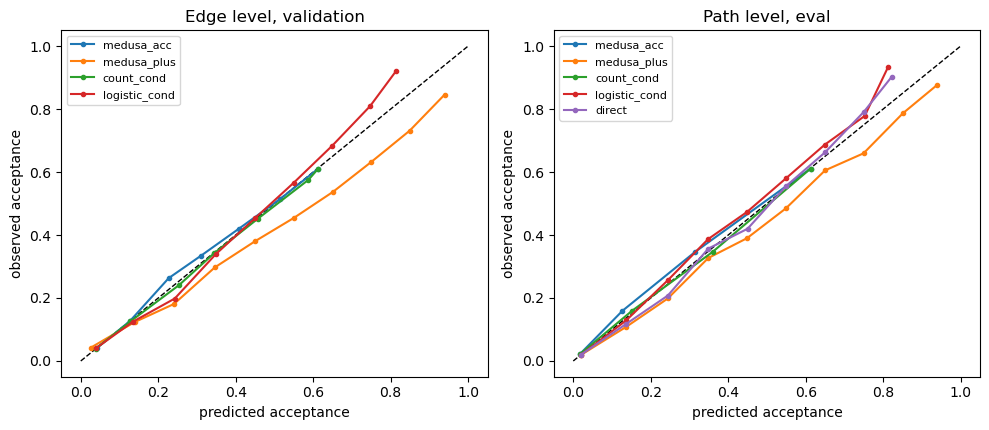

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, curves, title in [(axes[0], edge_curves, "Edge level, validation"),
                          (axes[1], path_curves, "Path level, " + ("eval" if evals is not None else "validation"))]:
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    for name, (mp, obs, cnt) in curves.items():
        ax.plot(mp, obs, "o-", ms=3, label=name)
    ax.set_xlabel("predicted acceptance"); ax.set_ylabel("observed acceptance")
    ax.set_title(title); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "reliability.png", dpi=150); plt.show()

## 9. Direct-classifier investigation

On synthetic data, the direct classifier trained on a MEDUSA+ pool loses accepted tokens as the budget
grows. The likely cause: it is trained only on nodes MEDUSA+ picks, but at large budgets its own trees
reach nodes it never saw. A weak baseline makes our result look better than it is, so we try three pools
and keep the best for the report:

1. MEDUSA+ trees at `POOL_BUDGET` (current).
2. Larger MEDUSA+ trees (128 nodes).
3. The current pool plus the nodes its own trees pick (one round of retraining, DAgger-style).

Selection uses validation prompts only (never MT-Bench). The `predicted` column is the sum of path scores
over the tree; close to `accepted` means the scorer knows how good its trees are.

In [18]:
def concat_pools(*pools):
    return NodeBatch.concat([p[0] for p in pools]), np.concatenate([p[1] for p in pools])

t0 = time.time()
mk = lambda: DirectClassifier(C=BEST_C, rank_cap=BEST_RANK_CAP)
pool_big = candidate_pool_nodes(train, ref, 128, POOL_STEPS // 2, seed=SEED)
pool_own = candidate_pool_nodes(train, [ref, scorers["direct"]], 96, POOL_STEPS // 2, seed=SEED + 1)
direct_variants = {
    "direct: MEDUSA+ pool": scorers["direct"],
    "direct: MEDUSA+ pool, 128 nodes": mk().fit(train, pool=pool_big),
    "direct: + own trees (1 round)": mk().fit(train, pool=concat_pools(pool_train, pool_own)),
}
print(f"variants fitted ({time.time() - t0:.0f}s)")

quick = np.sort(np.random.default_rng(SEED).choice(val.n_steps, min(QUICK_EVAL_STEPS, val.n_steps),
                                                   replace=False))
compare = {"medusa_plus": scorers["medusa_plus"], "logistic_cond": scorers["logistic_cond"],
           **direct_variants}
t0 = time.time()
rows = []
for B in [16, 63]:
    for name, sc in compare.items():
        r = evaluate_tree_policy(sc, val, B, steps=quick)
        rows.append(dict(budget=B, method=name, accepted=r["mean_accepted"], sem=r["sem_accepted"],
                         predicted=r["mean_predicted"]))
direct_df = pd.DataFrame(rows)
display(direct_df)
print(f"({time.time() - t0:.0f}s)")

at63 = direct_df[(direct_df.budget == 63) & direct_df.method.str.startswith("direct")]
BEST_DIRECT = at63.loc[at63.accepted.idxmax(), "method"]
scorers["direct"] = direct_variants[BEST_DIRECT]
print("Keeping for the report:", BEST_DIRECT)

variants fitted (80s)


,budget,method,accepted,sem,predicted
0,16,medusa_plus,2.9038,0.0445,3.1270
1,16,logistic_cond,2.9450,0.0409,2.9094
2,16,direct: MEDUSA+ pool,2.9175,0.0412,3.0209
3,16,"direct: MEDUSA+ pool, 128 nodes",2.9287,0.0413,2.9878
4,16,direct: + own trees (1 round),2.9312,0.0412,3.0197
5,63,medusa_plus,3.5638,0.0468,3.7584
6,63,logistic_cond,3.5950,0.0441,3.5505
7,63,direct: MEDUSA+ pool,3.3862,0.0414,3.8401
8,63,"direct: MEDUSA+ pool, 128 nodes",3.5463,0.0425,3.6449
9,63,direct: + own trees (1 round),3.5975,0.0436,3.6127


(66s)
Keeping for the report: direct: + own trees (1 round)


## 10. Feature-group ablation (logistic conditional)

Each row drops one feature group and refits. A larger `delta_brier` means the group matters more.
`parent_rank` and `interactions` carry the parent-child information the project is about.
Rerun this on the full traces for the report.

In [19]:
t0 = time.time()
full = LogisticConditional(C=BEST_C, rank_cap=BEST_RANK_CAP).fit(train, nodes=train_cond)
base_brier = brier(full.factor(val, val_cond[0]), val_cond[1])
rows = [dict(dropped="(none)", brier=base_brier, delta_brier=0.0)]
for g in FEATURE_GROUPS:
    sc = LogisticConditional(C=BEST_C, rank_cap=BEST_RANK_CAP, drop=(g,)).fit(train, nodes=train_cond)
    b = brier(sc.factor(val, val_cond[0]), val_cond[1])
    rows.append(dict(dropped=g, brier=b, delta_brier=b - base_brier))
ablation_df = pd.DataFrame(rows).sort_values("delta_brier", ascending=False)
display(ablation_df)
print(f"({time.time() - t0:.0f}s)")

,dropped,brier,delta_brier
4,confidence,0.0662,2.5349e-03
6,uncertainty,0.0644,7.1449e-04
7,interactions,0.0643,5.5547e-04
1,depth,0.0639,2.0707e-04
2,own_rank,0.0638,1.0120e-04
5,path_prob,0.0637,8.8234e-06
3,parent_rank,0.0637,8.7163e-06
0,(none),0.0637,0.0000e+00


(65s)


## 11. Save everything for the next step

* `models/<name>.pkl`: the five fitted scorers (load with `Scorer.load`; needs the same `mcal/` folder).
* `models/fixed_tree_<name>_B<budget>.json`: fixed trees in Medusa's `medusa_choices` format.
* `tables/*.csv`, `*.png`: calibration and tuning results for the report.
* `settings.json`: the chosen hyperparameters and which data they came from.
* `models_for_step3.zip`: `models/` plus the `mcal/` code, ready to send.

In [21]:
models_dir, tables_dir = OUT_DIR / "models", OUT_DIR / "tables"
models_dir.mkdir(parents=True, exist_ok=True); tables_dir.mkdir(parents=True, exist_ok=True)

for name, sc in scorers.items():
    sc.save(models_dir / f"{name}.pkl")

for name in ["medusa_acc", "count_cond"]:            # static scorers -> fixed trees
    for B in BUDGETS_FOR_ALEX:
        tree = fixed_tree(scorers[name], train, B)
        assert len(tree) == B and is_ancestor_closed(tree)
        (models_dir / f"fixed_tree_{name}_B{B}.json").write_text(json.dumps(tree_to_medusa_choices(tree)))

for df, fname in [(alpha_df, "alpha_tuning"), (grid_df, "logistic_tuning"), (edge_df, "calibration_edge"),
                  (path_df, "calibration_path"), (direct_df, "direct_variants"), (ablation_df, "feature_ablation")]:
    df.to_csv(tables_dir / f"{fname}.csv", index=False)

settings = dict(
    data="synthetic" if USE_SYNTHETIC else str(CALIB_FILE), trace_meta=calib.meta, split=split_how,
    train_prompts=int(len(np.unique(train.prompt_id))), val_prompts=int(len(np.unique(val.prompt_id))),
    count_alpha=BEST_ALPHA, logistic_C=BEST_C, rank_cap=BEST_RANK_CAP, direct_pool=BEST_DIRECT,
    pool_budget=POOL_BUDGET, pool_steps=POOL_STEPS, seed=SEED,
)
(OUT_DIR / "settings.json").write_text(json.dumps(settings, indent=2, default=str))

# Round-trip check: the saved files give the same scores when reloaded.
probe = NodeBatch(*[a[:500] for a in (val_cond[0].step, val_cond[0].path, val_cond[0].depth)])
for name, sc in scorers.items():
    again = Scorer.load(models_dir / f"{name}.pkl")
    assert np.allclose(again.path_scores(val, probe), sc.path_scores(val, probe)), name

bundle = OUT_DIR / "bundle"
shutil.rmtree(bundle, ignore_errors=True)
shutil.copytree(models_dir, bundle / "models")
shutil.copytree("mcal", bundle / "mcal", ignore=shutil.ignore_patterns("__pycache__"))
shutil.copy(OUT_DIR / "settings.json", bundle / "settings.json")
zip_path = shutil.make_archive(str(OUT_DIR / "models_for_step3"), "zip", bundle)
print("Saved:", sorted(p.name for p in models_dir.iterdir())[:6], "...")
print("Send to Alex:", zip_path)

Saved: ['count_cond.pkl', 'direct.pkl', 'fixed_tree_count_cond_B16.json', 'fixed_tree_count_cond_B32.json', 'fixed_tree_count_cond_B63.json', 'fixed_tree_count_cond_B8.json'] ...
Send to Alex: /home/z3qi/private/ECE285/proj/ECE_285_Final_Project/outputs_ada/models_for_step3.zip


## Next steps

* **When Lucia's pilot arrives:** set `USE_SYNTHETIC = False`, point `DATA_DIR` at her folder, run all,
  and send `models_for_step3.zip` to Alex even if rough, so he can test his pipeline.
* **When the full traces arrive:** rerun everything. The manifest split (200/50) takes over automatically.
* **For the report:** the edge-level calibration table, the reliability plot, the alpha curve (including the
  no-context ablation), the direct-classifier pool comparison and the feature ablation.
* **Synthetic numbers are for debugging only.** Never put them in the report.